# ==========================================
# CELL 1: SETUP, IMPORTS, AND CONFIGURATION
# ==========================================
# This cell imports all the required libraries and defines the input/output paths
# and the target variable as requested.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import itertools
import warnings

# ----------------- CONFIGURATION VARIABLES -----------------
# 1. Path variable for input dataset
INPUT_DATA_PATH = "Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Data/civils_samp.csv"

# 2. Path variable for output charts directory
OUTPUT_CHART_PATH = "Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/"

# 3. Target variable (must be a binary feature: 0 or 1, or two distinct classes)
TARGET_VARIABLE = "civils_fit"

# 4. Exclusion List (Variables to be dropped immediately from the analysis)
# Add names of columns you want to ignore (e.g., IDs, timestamps, unneeded features)
EXCLUDE_VARIABLES = ["work_order_uid", "icoms_premise_uid", "uprn", "entered_datetime"]
# -----------------------------------------------------------

# Create the output directory if it does not exist
os.makedirs(OUTPUT_CHART_PATH, exist_ok=True)

# Set the visualization style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)



# ==========================================
# CELL 1: SETUP, IMPORTS, AND CONFIGURATION
# ==========================================
# This cell imports all the required libraries, defines your input/output paths,
# sets up your target variable, and allows you to exclude specific variables 
# from the dataset prior to starting any exploratory data analysis.

# ==========================================
# CELL 2: DATA LOADING & PREPROCESSING
# ==========================================
# This cell loads the dataset, performs initial validation of the binary target,
# and automatically identifies numeric vs. categorical features

In [2]:
try:
    # Load the dataset
    df = pd.read_csv(INPUT_DATA_PATH)
    print(f"Successfully loaded dataset of shape: {df.shape}\n")
    
    # Check if target variable exists in the dataframe
    if TARGET_VARIABLE not in df.columns:
        raise ValueError(f"Target variable '{TARGET_VARIABLE}' not found in the dataset columns.")
        
    # Drop rows where target is missing
    df = df.dropna(subset=[TARGET_VARIABLE])
    
    # Ensure target is binary
    unique_targets = df[TARGET_VARIABLE].unique()
    if len(unique_targets) != 2:
        print(f"Warning: Target column '{TARGET_VARIABLE}' does not have exactly 2 classes. Found: {unique_targets}")
    
    # Automatically identify feature types (excluding the target)
    input_features = [col for col in df.columns if col != TARGET_VARIABLE]
    
    numeric_features = []
    categorical_features = []
    
    for col in input_features:
        # If numeric and has more than 10 unique values, classify as numeric
        if pd.api.types.is_numeric_dtype(df[col]) and df[col].nunique() > 10:
            numeric_features.append(col)
        else:
            categorical_features.append(col)
            
    print(f"Identified {len(numeric_features)} Numeric Features: {numeric_features}")
    print(f"Identified {len(categorical_features)} Categorical Features: {categorical_features}")

except Exception as e:
    print(f"Error during data loading: {e}")
    print("Please make sure to set a valid 'INPUT_DATA_PATH' in Cell 1.")


C:\Users\M1448898\AppData\Local\Temp\ipykernel_12364\1293496083.py:3: DtypeWarning: Columns (0: is_wayleave, 1: is_listed_building, 2: is_new_dev, 3: drop_cables_pre_pulled, 4: is_sdu, 5: is_small_mdu, 6: is_prewire) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(INPUT_DATA_PATH)


Successfully loaded dataset of shape: (20000, 417)

Identified 287 Numeric Features: ['account_occurrence', 'days_entered_to_original_schedule', 'days_since_first_connection', 'building_premise_count', 'days_since_serviceable', 'days_vacant', 'prior_customer_count', 'inactive_account_gap', 'days_since_last_cp', 'premise_orders_0_12m', 'premise_reschedule_count_0_12m', 'premise_cp_rate_0_12m', 'premise_civils_rate_0_12m', 'premise_reschedule_rate_0_12m', 'premise_civils_reschedule_rate_0_12m', 'premise_avg_days_to_schedule_0_12m', 'premise_avg_days_to_schedule_12_36m', 'network_element_orders_0_3m', 'network_element_cp_count_0_3m', 'network_element_reschedule_count_0_3m', 'network_element_unique_premises_0_3m', 'network_element_cp_rate_0_3m', 'network_element_civils_rate_0_3m', 'network_element_reschedule_rate_0_3m', 'network_element_civils_reschedule_rate_0_3m', 'network_element_avg_days_to_schedule_0_3m', 'network_element_orders_3_12m', 'network_element_cp_count_3_12m', 'network_eleme

# ==========================================
# CELL 3: CATEGORICAL FEATURE ANALYSIS (Step 4)
# ==========================================
# This cell generates bar charts showing the relationship of each categorical 
# input feature against the target. Proportions of the target classes are plotted 
# to easily compare groups of different sizes.

In [3]:
print("Generating and saving bar charts for categorical features...")

for col in categorical_features:
    plt.figure(figsize=(10, 6))
    
    # Plot normalized percentages of the target class per category group
    # to avoid raw-count skewness if groups have imbalanced sizes
    df_prop = (df.groupby(col)[TARGET_VARIABLE]
               .value_counts(normalize=True)
               .rename("Percentage")
               .reset_index())
    
    # Convert proportion to actual percentage
    df_prop["Percentage"] *= 100
    
    sns.barplot(x=col, y="Percentage", hue=TARGET_VARIABLE, data=df_prop, palette="viridis")
    
    plt.title(f"Target Distribution by {col}", fontsize=14, fontweight='bold')
    plt.xlabel(col, fontsize=12)
    plt.ylabel("Percentage (%)", fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.legend(title=TARGET_VARIABLE)
    plt.tight_layout()
    
    # Save chart to designated folder
    filename = os.path.join(OUTPUT_CHART_PATH, f"bar_chart_{col}_vs_{TARGET_VARIABLE}.png")
    plt.savefig(filename, dpi=150)
    plt.close()
    
    print(f" - Saved: {filename}")

print("Categorical feature plotting complete.")


Generating and saving bar charts for categorical features...
 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/bar_chart_instance_wo_count_vs_civils_fit.png
 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/bar_chart_crew_type_vs_civils_fit.png
 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/bar_chart_schedule_lead_bucket_vs_civils_fit.png
 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/bar_chart_dwelling_type_vs_civils_fit.png
 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/bar_chart_rgu_count_vs_civils_fit.png
 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/bar_chart_has_tv_vs_civils_fit.png
 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/bar_chart_has_broadband_vs

C:\Users\M1448898\AppData\Local\Temp\ipykernel_12364\3323333536.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title=TARGET_VARIABLE)


 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/bar_chart_former_normer_never_vs_civils_fit.png
 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/bar_chart_prewired_flag_vs_civils_fit.png
 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/bar_chart_wayleave_agreement_flag_vs_civils_fit.png


C:\Users\M1448898\AppData\Local\Temp\ipykernel_12364\3323333536.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title=TARGET_VARIABLE)


 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/bar_chart_student_premise_flag_vs_civils_fit.png
 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/bar_chart_prem_dwelling_type_code_vs_civils_fit.png
 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/bar_chart_wayleave_required_vs_civils_fit.png
 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/bar_chart_listed_building_vs_civils_fit.png
 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/bar_chart_drop_cables_pre_pulled_vs_civils_fit.png
 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/bar_chart_construction_status_vs_civils_fit.png
 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/bar_chart_is_sdu_vs_civils_fit.png
 - Saved: 

# ==========================================
# CELL 4: NUMERICAL FEATURE ANALYSIS (Step 5)
# ==========================================
# This cell generates box plots for each numeric feature grouped by the binary target.

In [4]:
print("Generating and saving box plots for numerical features...")

for col in numeric_features:
    plt.figure(figsize=(10, 6))
    
    sns.boxplot(x=TARGET_VARIABLE, y=col, data=df, palette="Set2")
    
    plt.title(f"Distribution of {col} by {TARGET_VARIABLE}", fontsize=14, fontweight='bold')
    plt.xlabel(TARGET_VARIABLE, fontsize=12)
    plt.ylabel(col, fontsize=12)
    plt.tight_layout()
    
    # Save chart to designated folder
    filename = os.path.join(OUTPUT_CHART_PATH, f"boxplot_{col}_vs_{TARGET_VARIABLE}.png")
    plt.savefig(filename, dpi=150)
    plt.close()
    
    print(f" - Saved: {filename}")

print("Numerical feature plotting complete.")


Generating and saving box plots for numerical features...


C:\Users\M1448898\AppData\Local\Temp\ipykernel_12364\2551457190.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=TARGET_VARIABLE, y=col, data=df, palette="Set2")


 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/boxplot_account_occurrence_vs_civils_fit.png


C:\Users\M1448898\AppData\Local\Temp\ipykernel_12364\2551457190.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=TARGET_VARIABLE, y=col, data=df, palette="Set2")


 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/boxplot_days_entered_to_original_schedule_vs_civils_fit.png


C:\Users\M1448898\AppData\Local\Temp\ipykernel_12364\2551457190.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=TARGET_VARIABLE, y=col, data=df, palette="Set2")


... (565 outputs left out)

C:\Users\M1448898\AppData\Local\Temp\ipykernel_12364\2551457190.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=TARGET_VARIABLE, y=col, data=df, palette="Set2")


 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/boxplot_alt_net_count_vs_civils_fit.png


C:\Users\M1448898\AppData\Local\Temp\ipykernel_12364\2551457190.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=TARGET_VARIABLE, y=col, data=df, palette="Set2")


 - Saved: Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/boxplot_Estimated_Population_vs_civils_fit.png
Numerical feature plotting complete.


# ==========================================
# CELL 5: STATISTICAL SIGNIFICANCE SUMMARY (Step 6)
# ==========================================
# This cell executes statistical tests to determine if relationships with the target 
# are statistically significant and whether they are positive or negative.
# - Categorical: Chi-Square Test of Independence + Direction based on risk/rate ratio
# - Numerical: Mann-Whitney U test (non-parametric t-test) + Point-Biserial Correlation (for direction)

In [5]:
summary_results = []
ALPHA = 0.05  # Significance threshold

# 1. Evaluate Categorical Features using Chi-Square Test
for col in categorical_features:
    # Build contingency table
    contingency = pd.crosstab(df[col], df[TARGET_VARIABLE])
    
    # Skip if table is empty or single-valued
    if contingency.size < 4:
        continue
        
    chi2, p_val, dof, expected = stats.chi2_contingency(contingency)
    is_sig = p_val < ALPHA
    
    # Directionality metric: compare target rate between the first two unique groups
    categories = list(contingency.index)
    if len(categories) >= 2:
        # Calculate target rate (assuming binary 0 and 1)
        rate_cat0 = contingency.loc[categories[0], 1] / contingency.loc[categories[0]].sum() if 1 in contingency.columns else 0
        rate_cat1 = contingency.loc[categories[1], 1] / contingency.loc[categories[1]].sum() if 1 in contingency.columns else 0
        direction = f"Rate is higher in '{categories[1]}' than '{categories[0]}'" if rate_cat1 > rate_cat0 else f"Rate is lower in '{categories[1]}' than '{categories[0]}'"
    else:
        direction = "N/A (Single group)"
        
    summary_results.append({
        "Feature": col,
        "Type": "Categorical",
        "Test Metric": f"Chi-Square ({chi2:.2f})",
        "P-Value": round(p_val, 5),
        "Significant?": "Yes" if is_sig else "No",
        "Relationship Direction/Pattern": direction if is_sig else "No significant relationship"
    })

# 2. Evaluate Numerical Features using Mann-Whitney U Test & Correlation
for col in numeric_features:
    # Drop rows with NaNs in this specific feature
    temp_df = df[[col, TARGET_VARIABLE]].dropna()
    
    # Validation check to ensure we have exactly 2 distinct classes present
    # in the target for this column after dropping missing data
    active_classes = temp_df[TARGET_VARIABLE].unique()
    if len(active_classes) < 2:
        print(f" -> Skipping '{col}': Insufficient target class representation after dropping missing values.")
        continue
    
    # Safely split groups using validated active classes
    group0 = temp_df[temp_df[TARGET_VARIABLE] == active_classes[0]][col]
    group1 = temp_df[temp_df[TARGET_VARIABLE] == active_classes[1]][col]
    
    # Conduct Mann-Whitney U Test
    stat, p_val = stats.mannwhitneyu(group0, group1)
    is_sig = p_val < ALPHA
    
    # Directionality based on point-biserial correlation
    try:
        corr_coef, _ = stats.pointbiserialr(temp_df[TARGET_VARIABLE].astype(float), temp_df[col])
        direction = "Positive (Higher values correspond to Target=1)" if corr_coef > 0 else "Negative (Lower values correspond to Target=1)"
    except:
        direction = "Unknown"
        
    summary_results.append({
        "Feature": col,
        "Type": "Numerical",
        "Test Metric": f"Mann-Whitney U ({stat:.2f})",
        "P-Value": round(p_val, 5),
        "Significant?": "Yes" if is_sig else "No",
        "Relationship Direction/Pattern": direction if is_sig else "No significant relationship"
    })

# Construct Summary DataFrame
summary_df = pd.DataFrame(summary_results)

print("\n--- STATISTICAL SIGNIFICANCE SUMMARY TABLE ---")
display(summary_df)

# =====================================================================
# EXPORT SUMMARY TO EXCEL
# =====================================================================
excel_filename = "statistical_significance_summary.xlsx"
excel_output_path = os.path.join(OUTPUT_CHART_PATH, excel_filename)

try:
    # Save the file without the index column for a cleaner look
    summary_df.to_excel(excel_output_path, sheet_name="Significance Summary", index=False)
    print(f"\n[✔] Success: Statistical summary table successfully saved to:\n    -> {excel_output_path}")
except Exception as e:
    print(f"\n[❌] Error saving Excel file: {e}")
    print("Please make sure you have the 'openpyxl' library installed ('pip install openpyxl') and the folder path exists.")


--- STATISTICAL SIGNIFICANCE SUMMARY TABLE ---


,Feature,Type,Test Metric,P-Value,Significant?,Relationship Direction/Pattern
0,instance_wo_count,Categorical,Chi-Square (32.03),0.00000,Yes,Rate is higher in '2' than '1'
1,schedule_lead_bucket,Categorical,Chi-Square (30.92),0.00001,Yes,Rate is lower in '15-28_extended' than '0-3_ur...
2,dwelling_type,Categorical,Chi-Square (270.65),0.00000,Yes,Rate is lower in '2' than '1'
3,rgu_count,Categorical,Chi-Square (14.85),0.03794,Yes,Rate is higher in '2.0' than '1.0'
4,has_tv,Categorical,Chi-Square (1.81),0.17795,No,No significant relationship
...,...,...,...,...,...,...
382,franchise_total_premises,Numerical,Mann-Whitney U (35003402.50),0.00000,Yes,Negative (Lower values correspond to Target=1)
383,franchise_served_premises,Numerical,Mann-Whitney U (34887868.50),0.00000,Yes,Negative (Lower values correspond to Target=1)
384,franchise_served_pct,Numerical,Mann-Whitney U (37618529.50),0.73742,No,No significant relationship
385,alt_net_count,Numerical,Mann-Whitney U (37707638.00),0.30710,No,No significant relationship



[✔] Success: Statistical summary table successfully saved to:
    -> Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/statistical_significance_summary.xlsx


# ==========================================
# CELL 6: MULTI-COLLINEARITY ANALYSIS (Step 7)
# ==========================================
# This cell filters out non-significant features and checks for multi-collinearity 
# among the remaining significant features using correlation thresholds.

Significant features going into correlation check: ['instance_wo_count', 'schedule_lead_bucket', 'dwelling_type', 'rgu_count', 'bb_serviceability_code', 'is_new_dev', 'is_lightning', 'prewired_flag', 'prem_dwelling_type_code', 'construction_status', 'is_sdu', 'is_small_mdu', 'is_prewire', 'dna_address_type', 'premise_cp_count_0_12m', 'premise_civils_count_0_12m', 'network_element_civils_count_0_3m', 'network_element_civils_count_3_12m', 'network_element_civils_count_12_36m', 'postcode_civils_count_12_36m', 'c_cluster_nd_count_12_36m', 'circle_10m_civils_count_0_3m', 'circle_10m_civils_reschedule_count_0_3m', 'circle_10m_civils_rate_0_3m', 'circle_10m_civils_reschedule_rate_0_3m', 'circle_20m_civils_count_0_3m', 'circle_20m_civils_reschedule_count_0_3m', 'circle_20m_civils_count_3_12m', 'circle_20m_civils_reschedule_count_3_12m', 'circle_20m_civils_reschedule_count_12_36m', 'circle_50m_civils_count_0_3m', 'circle_50m_civils_reschedule_count_0_3m', 'circle_50m_civils_count_3_12m', 'circl

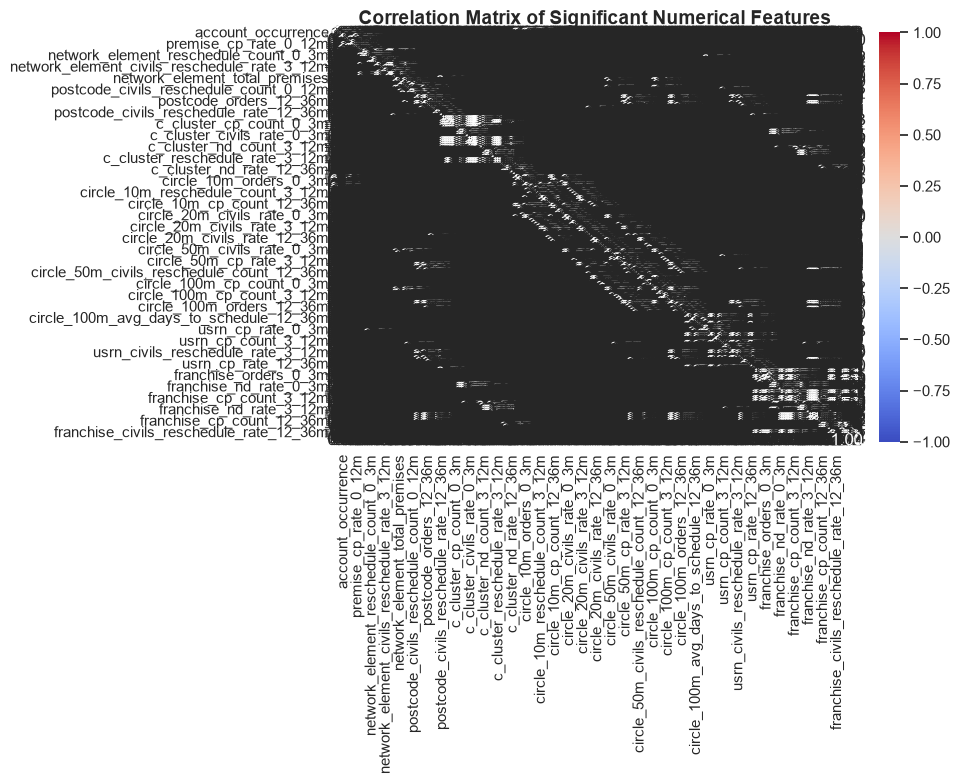

Highly correlated numeric feature pairs (> 0.7):
 - inactive_account_gap and account_occurrence: Correlation = 0.88
 - premise_reschedule_rate_0_12m and premise_reschedule_count_0_12m: Correlation = 0.92
 - premise_civils_reschedule_rate_0_12m and premise_reschedule_count_0_12m: Correlation = 0.76
 - premise_civils_reschedule_rate_0_12m and premise_reschedule_rate_0_12m: Correlation = 0.72
 - network_element_civils_reschedule_count_12_36m and network_element_reschedule_count_12_36m: Correlation = 0.86
 - network_element_civils_reschedule_rate_12_36m and network_element_reschedule_rate_12_36m: Correlation = 0.70
 - network_element_total_premises and network_element_reschedule_count_0_3m: Correlation = 0.73
 - network_element_total_premises and network_element_reschedule_count_12_36m: Correlation = 0.74
 - network_element_served_premises and network_element_reschedule_count_0_3m: Correlation = 0.73
 - network_element_served_premises and network_element_reschedule_count_12_36m: Correlatio

In [6]:
# Filter only significant features
sig_features_info = summary_df[summary_df["Significant?"] == "Yes"]
sig_features = sig_features_info["Feature"].tolist()

print(f"Significant features going into correlation check: {sig_features}\n")

correlated_pairs = []

if len(sig_features) > 1:
    # Isolate numerical significant features
    sig_num_features = [f for f in sig_features if f in numeric_features]
    
    # Check numeric correlations
    if len(sig_num_features) > 1:
        corr_matrix = df[sig_num_features].corr(method='pearson')
        
        # Plot numeric correlation heatmap
        plt.figure(figsize=(10, 8))
        sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
        plt.title("Correlation Matrix of Significant Numerical Features", fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(os.path.join(OUTPUT_CHART_PATH, "correlation_heatmap_numerical.png"), dpi=150)
        plt.show()
        
        # Identify pairs with high correlation (> 0.7)
        high_corr_threshold = 0.7
        upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
        
        correlated_pairs = [
            (column, row, upper_tri.loc[row, column])
            for column in upper_tri.columns
            for row in upper_tri.index
            if abs(upper_tri.loc[row, column]) > high_corr_threshold
        ]
        
        if correlated_pairs:
            print("Highly correlated numeric feature pairs (> 0.7):")
            for col1, col2, val in correlated_pairs:
                print(f" - {col1} and {col2}: Correlation = {val:.2f}")
        else:
            print("No highly correlated numerical features found.")
            correlated_pairs = []
    else:
        print("Fewer than 2 significant numerical features. Skipping Pearson correlation.")
        correlated_pairs = []
else:
    print("Not enough significant features to conduct correlation analysis.")
    correlated_pairs = []

# =====================================================================
# ADDED CODE: EXPORT COLLINEARITY TO EXCEL
# =====================================================================
# Convert the list of correlated pairs to a DataFrame and export to Excel

excel_filename = "detected_collinearity_summary.xlsx"
excel_output_path = os.path.join(OUTPUT_CHART_PATH, excel_filename)

try:
    if correlated_pairs:
        # Create a clean structured DataFrame of the collinear pairs
        collinearity_df = pd.DataFrame(
            correlated_pairs, 
            columns=["Feature A", "Feature B", "Pearson Correlation Coefficient"]
        )
        # Sort by absolute correlation magnitude descending
        collinearity_df = collinearity_df.reindex(
            collinearity_df["Pearson Correlation Coefficient"].abs().sort_values(ascending=False).index
        )
    else:
        # Create a placeholder DataFrame if no collinearity was found
        collinearity_df = pd.DataFrame([{
            "Status": "No highly correlated numerical features (> 0.7) were detected among significant inputs."
        }])
        
    # Save the dataframe to Excel
    collinearity_df.to_excel(excel_output_path, sheet_name="Collinearity Analysis", index=False)
    print(f"\n[✔] Success: Collinearity summary successfully saved to:\n    -> {excel_output_path}")

except Exception as e:
    print(f"\n[❌] Error saving collinearity Excel file: {e}")


# ==========================================
# CELL 7: FINAL FEATURE RECOMMENDATION (Step 8)
# ==========================================
# This cell executes selection logic: For each pair of highly correlated features, 
# it identifies the weaker performing feature (the one with the larger/less significant p-value) 
# and automatically recommends dropping it, leaving a clean set of features for your model.

In [7]:
features_to_drop = set()
elimination_reasons = {} # Tracks why a feature was dropped and by which counterpart

if 'correlated_pairs' in locals() and correlated_pairs:
    print("Analyzing correlated pairs to identify weaker features...")
    for col1, col2, corr_val in correlated_pairs:
        # Fetch their p-values from our statistical test summary
        p_col1 = summary_df.loc[summary_df["Feature"] == col1, "P-Value"].values[0]
        p_col2 = summary_df.loc[summary_df["Feature"] == col2, "P-Value"].values[0]
        
        # Drop the one with the higher (weaker, larger) p-value
        if p_col1 > p_col2:
            features_to_drop.add(col1)
            elimination_reasons[col1] = f"Dropped due to high correlation ({corr_val:.2f}) with '{col2}' which has higher significance (p={p_col2} vs p={p_col1})"
            print(f" -> Recommending to drop '{col1}' (p={p_col1}) over '{col2}' (p={p_col2}) due to lower significance.")
        else:
            features_to_drop.add(col2)
            elimination_reasons[col2] = f"Dropped due to high correlation ({corr_val:.2f}) with '{col1}' which has higher significance (p={p_col1} vs p={p_col2})"
            print(f" -> Recommending to drop '{col2}' (p={p_col2}) over '{col1}' (p={p_col1}) due to lower significance.")

# Get final list of recommended features
final_recommended_features = [f for f in sig_features if f not in features_to_drop]

print("\n=======================================================")
print("             CRISP-DM STAGE ANALYSIS RESULTS           ")
print("=======================================================")
print(f"Total Initial Features Investigated : {len(input_features)}")
print(f"Statistically Significant Features  : {len(sig_features)}")
print(f"Features Eliminated (Collinearity)  : {list(features_to_drop)}")
print(f"FINAL RECOMMENDED FEATURES FOR MODEL: {final_recommended_features}")
print("=======================================================")

# =====================================================================
# ADDED CODE: EXPORT FINAL RECOMMENDATIONS TO MULTI-SHEET EXCEL
# =====================================================================
excel_filename = "final_feature_recommendation.xlsx"
excel_output_path = os.path.join(OUTPUT_CHART_PATH, excel_filename)

try:
    # 1. Build an audit trail tracking decisions for ALL initial features
    audit_records = []
    for col in input_features:
        # Determine its significance status
        is_sig = col in sig_features
        # Determine its decision
        if not is_sig:
            status = "DROP (Not Statistically Significant)"
            reason = "Failed significance threshold (p >= 0.05)"
        elif col in features_to_drop:
            status = "DROP (High Collinearity)"
            reason = elimination_reasons.get(col, "Dropped due to collinearity with stronger feature.")
        else:
            status = "KEEP"
            reason = "Statistically significant; passed collinearity checks."
            
        audit_records.append({
            "Feature Name": col,
            "Statistical Significance (p < 0.05)": "Yes" if is_sig else "No",
            "Selection Decision": status,
            "Decision Reason": reason
        })
    
    decision_audit_df = pd.DataFrame(audit_records)
    
    # 2. Build a minimal dataframe containing just the modeling columns
    modeling_features_df = pd.DataFrame(final_recommended_features, columns=["Recommended Modeling Features"])
    
    # 3. Write both to a single Excel workbook using ExcelWriter
    with pd.ExcelWriter(excel_output_path, engine="openpyxl") as writer:
        decision_audit_df.to_excel(writer, sheet_name="Selection Decision", index=False)
        modeling_features_df.to_excel(writer, sheet_name="Final Modeling Features", index=False)
        
    print(f"\n[✔] Success: Final recommendations and audit trail successfully saved to:\n    -> {excel_output_path}")

except Exception as e:
    print(f"\n[❌] Error saving final recommendation Excel file: {e}")


Analyzing correlated pairs to identify weaker features...
 -> Recommending to drop 'account_occurrence' (p=0.0) over 'inactive_account_gap' (p=0.0) due to lower significance.
 -> Recommending to drop 'premise_reschedule_count_0_12m' (p=0.0001) over 'premise_reschedule_rate_0_12m' (p=0.0001) due to lower significance.
 -> Recommending to drop 'premise_civils_reschedule_rate_0_12m' (p=0.00018) over 'premise_reschedule_count_0_12m' (p=0.0001) due to lower significance.
 -> Recommending to drop 'premise_civils_reschedule_rate_0_12m' (p=0.00018) over 'premise_reschedule_rate_0_12m' (p=0.0001) due to lower significance.
 -> Recommending to drop 'network_element_reschedule_count_12_36m' (p=0.00271) over 'network_element_civils_reschedule_count_12_36m' (p=1e-05) due to lower significance.
 -> Recommending to drop 'network_element_reschedule_rate_12_36m' (p=0.00385) over 'network_element_civils_reschedule_rate_12_36m' (p=2e-05) due to lower significance.
 -> Recommending to drop 'network_elemen

# =====================================================================
# CELL 8: TARGET-VALDATED BIGQUERY FEATURE ENGINEERING (Step 9)
# =====================================================================
# This cell takes 'final_recommended_features' (from Cell 7) and:
# 1. Combines ONLY uncorrelated features (|r| < 0.3).
# 2. Computes the combined features on your sampled dataframe.
# 3. Validates them using Mann-Whitney U Tests against your target.
# 4. Selects only the "super-features" that have a stronger relationship 
#    with the target than their parent features did.
# 5. Generates production-ready BigQuery SQL statements for these top performers.

In [8]:
print(f"Beginning Target-Validated SQL Feature Engineering on: {TARGET_VARIABLE}...")

# Filter out SciPy ConstantInputWarnings dynamically to keep output clean
warnings.filterwarnings('ignore', category=stats.ConstantInputWarning)

final_numeric = [f for f in final_recommended_features if f in numeric_features]
final_categorical = [f for f in final_recommended_features if f in categorical_features]

engineered_results = []
ALPHA = 0.05

# Establish the baseline target correlations of parent features
parent_corrs = {}
for col in final_numeric:
    try:
        # Fill missing values temporarily with median to get a robust baseline correlation
        filled_parent = df[col].fillna(df[col].median())
        if filled_parent.nunique() > 1:
            corr_val, _ = stats.pointbiserialr(df[TARGET_VARIABLE].astype(float), filled_parent)
            parent_corrs[col] = abs(corr_val)
        else:
            parent_corrs[col] = 0.0
    except:
        parent_corrs[col] = 0.0

if len(final_numeric) > 1:
    print("-> Analyzing numerical combinations...")
    # Calculate a correlation matrix to identify collinear features
    corr_matrix = df[final_numeric].corr(method='pearson')

    # Iterate through unique pairs
    for col1, col2 in itertools.combinations(final_numeric, 2):
        r_between_parents = corr_matrix.loc[col1, col2]

        # RULE 1: Do not combine features that are already correlated (|r| >= 0.3)
        if abs(r_between_parents) >= 0.3 or np.isnan(r_between_parents):
            continue

        # Temporarily create the proposed combined variables on our local sample
        temp_df = df[[col1, col2, TARGET_VARIABLE]].copy()

        # Fill NaNs with median for statistical calculations
        temp_df[col1] = temp_df[col1].fillna(temp_df[col1].median())
        temp_df[col2] = temp_df[col2].fillna(temp_df[col2].median())

        # Define combinations
        temp_df['prod'] = temp_df[col1] * temp_df[col2]
        # Use safe local division (handling zeros cleanly by converting to NaN)
        temp_df['ratio_1'] = temp_df[col1] / temp_df[col2]
        temp_df['ratio_2'] = temp_df[col2] / temp_df[col1]

        combinations_to_test = [
            ('prod', f"{col1} * {col2}", f"{col1}_x_{col2}", "Multiplication"),
            ('ratio_1', f"SAFE_DIVIDE({col1}, {col2})", f"{col1}_ratio_{col2}", f"Ratio ({col1} / {col2})"),
            ('ratio_2', f"SAFE_DIVIDE({col2}, {col1})", f"{col2}_ratio_{col1}", f"Ratio ({col2} / {col1})")
        ]

        for temp_col_name, sql_formula, bq_alias, comb_type in combinations_to_test:
            # Replace infinities with NaN and drop missing values
            test_df = temp_df[[temp_col_name, TARGET_VARIABLE]].replace([np.inf, -np.inf], np.nan).dropna()

            # Skip if the newly engineered feature has 1 or fewer unique values
            if test_df[temp_col_name].nunique() <= 1:
                continue

            # Ensure class balance exists in local slice
            u_classes = test_df[TARGET_VARIABLE].unique()
            if len(u_classes) < 2:
                continue

            g0 = test_df[test_df[TARGET_VARIABLE] == u_classes[0]][temp_col_name]
            g1 = test_df[test_df[TARGET_VARIABLE] == u_classes[1]][temp_col_name]  # <--- CRITICAL FIX APPLIED HERE

            # Evaluate combination against the target label (Mann-Whitney)
            stat, p_val = stats.mannwhitneyu(g0, g1)

            # Calculate correlation of the engineered feature with the target
            try:
                combo_corr, _ = stats.pointbiserialr(test_df[TARGET_VARIABLE].astype(float), test_df[temp_col_name])
                combo_corr_abs = abs(combo_corr)
            except:
                combo_corr_abs = 0.0

            # Check baseline parent correlations
            parent1_baseline = parent_corrs.get(col1, 0.0)
            parent2_baseline = parent_corrs.get(col2, 0.0)
            max_parent_baseline = max(parent1_baseline, parent2_baseline)

            # RULE 2 & 3: Must be statistically significant (p < 0.05) AND
            # show a stronger relationship with the target than either parent did individually
            if p_val < ALPHA and combo_corr_abs > max_parent_baseline:
                engineered_results.append({
                    "Engineered Feature": bq_alias,
                    "Type": comb_type,
                    "Parent 1": col1,
                    "Parent 2": col2,
                    "Correlation with Target (Combo)": round(combo_corr_abs, 4),
                    "Correlation with Target (Best Parent)": round(max_parent_baseline, 4),
                    "Improvement Over Parents": round(combo_corr_abs - max_parent_baseline, 4),
                    "P-Value": round(p_val, 5),
                    "BigQuery SQL Formulation": f"{sql_formula} AS {bq_alias}"
                })

# Build the DataFrame
engineered_df = pd.DataFrame(engineered_results)

# Sort results to bubble the absolute best-performing "super-features" to the top
if not engineered_df.empty:
    engineered_df = engineered_df.sort_values(by="Improvement Over Parents", ascending=False).reset_index(drop=True)
    # Cap selection to the top 5 highest-performing features to keep the list focused and non-exhaustive
    engineered_df = engineered_df.head(5)

print("\n=======================================================")
print("     TARGET-VALIDATED TOP BIGQUERY FEATURES SELECTED   ")
print("=======================================================")
if not engineered_df.empty:
    display(engineered_df)
else:
    print("No engineered features outperformed their parent variables. Stick with your baseline recommended features.")
print("=======================================================")

# Append these refined recommendations to your final Excel workbook
rec_excel_path = os.path.join(OUTPUT_CHART_PATH, "final_feature_recommendation.xlsx")

try:
    if os.path.exists(rec_excel_path):
        import openpyxl
        book = openpyxl.load_workbook(rec_excel_path)

        # Delete the sheet if it already exists to prevent duplication
        if "Feature Engineering Recs" in book.sheetnames:
            del book["Feature Engineering Recs"]

        with pd.ExcelWriter(rec_excel_path, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
            engineered_df.to_excel(writer, sheet_name="Feature Engineering Recs", index=False)
        print(f"\n[✔] Success: Added top validated 'Feature Engineering Recs' sheet to your existing workbook:\n    -> {rec_excel_path}")
    else:
        engineered_df.to_excel(rec_excel_path, sheet_name="Feature Engineering Recs", index=False)
        print(f"\n[✔] Success: Created feature engineering workbook at:\n    -> {rec_excel_path}")
except Exception as e:
    print(f"\n[❌] Error saving validated Feature Engineering Excel: {e}")

Beginning Target-Validated SQL Feature Engineering on: civils_fit...
-> Analyzing numerical combinations...

     TARGET-VALIDATED TOP BIGQUERY FEATURES SELECTED   


,Engineered Feature,Type,Parent 1,Parent 2,Correlation with Target (Combo),Correlation with Target (Best Parent),Improvement Over Parents,P-Value,BigQuery SQL Formulation
0,network_element_total_premises_ratio_premise_a...,Ratio (network_element_total_premises / premis...,premise_avg_days_to_schedule_12_36m,network_element_total_premises,0.3210,0.0234,0.2976,0.00778,"SAFE_DIVIDE(network_element_total_premises, pr..."
1,circle_50m_cp_rate_12_36m_ratio_premise_avg_da...,Ratio (circle_50m_cp_rate_12_36m / premise_avg...,premise_avg_days_to_schedule_12_36m,circle_50m_cp_rate_12_36m,0.3354,0.0379,0.2975,0.01900,"SAFE_DIVIDE(circle_50m_cp_rate_12_36m, premise..."
2,usrn_civils_reschedule_rate_0_3m_ratio_circle_...,Ratio (usrn_civils_reschedule_rate_0_3m / circ...,circle_20m_civils_rate_0_3m,usrn_civils_reschedule_rate_0_3m,0.3272,0.0316,0.2956,0.00431,"SAFE_DIVIDE(usrn_civils_reschedule_rate_0_3m, ..."
3,usrn_cp_rate_0_3m_ratio_circle_20m_civils_resc...,Ratio (usrn_cp_rate_0_3m / circle_20m_civils_r...,circle_20m_civils_reschedule_rate_0_3m,usrn_cp_rate_0_3m,0.3274,0.0346,0.2927,0.03913,"SAFE_DIVIDE(usrn_cp_rate_0_3m, circle_20m_civi..."
4,c_cluster_avg_days_to_schedule_0_3m_ratio_circ...,Ratio (c_cluster_avg_days_to_schedule_0_3m / c...,c_cluster_avg_days_to_schedule_0_3m,circle_20m_civils_reschedule_rate_0_3m,0.3258,0.0346,0.2912,0.03247,SAFE_DIVIDE(c_cluster_avg_days_to_schedule_0_3...



[✔] Success: Added top validated 'Feature Engineering Recs' sheet to your existing workbook:
    -> Z:/Internal/Data Science/Projects/DS007 Civils Regional Modelling/Results/EDA charts/final_feature_recommendation.xlsx
